# DSR301m – MLP (Deep Learning đối chứng) + Calibration + Selective Classification
XGBoost vẫn là mô hình đề xuất của paper; **MLP là baseline Deep Learning** để kiểm tra: *neural network có cải thiện phân loại, hiệu chuẩn xác suất và selective prediction trên WESAD không?*

**Pipeline (7 bước của nhóm) và cách notebook thực hiện**

| Bước | Thực hiện |
|---|---|
| 1. Dataset | 25 đặc trưng, nhãn Stress/Non-Stress; `subject_id`, `time_*` chỉ dùng để chia nhóm |
| 2. Chia theo subject | LOSO ngoài (15 fold) + **GroupKFold(3) theo subject bên trong** (giống paper) |
| 3. Tiền xử lý | `StandardScaler` fit chỉ trên 14 subject train của mỗi fold |
| 4. MLP | 25 → 64 → 32 → 1, ReLU, Dropout 0.2, Adam 1e-3, BCE, **early stopping theo subject** |
| 5. Hiệu chuẩn | Isotonic và Temperature Scaling, **chọn calibrator trong inner validation** (Brier thấp hơn) |
| 6. Selective | Stress / Non-Stress / Uncertain; **τ chọn trong inner validation**, không mặc định 0.80 |
| 7. Đánh giá | Macro F1, Stress F1, BalAcc, ECE, Brier, Coverage, Selective Risk, FAR_motion, theo subject + kiểm định |

**Nguyên tắc chống rò rỉ:** nhãn của subject test không bao giờ được dùng để huấn luyện, early stopping, hiệu chuẩn hay chọn τ.

**So sánh công bằng:** XGBoost và Random Forest chạy trong *cùng notebook*, cùng fold, cùng cách hiệu chuẩn (ensemble 3 mô hình nội bộ + Isotonic, như `CalibratedClassifierCV`) và cùng quy tắc chọn τ.

## 0. Cài đặt & cấu hình

In [1]:
!pip -q install xgboost

import os, glob, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from scipy.optimize import minimize_scalar
from scipy.stats import wilcoxon
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.isotonic import IsotonicRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             roc_auc_score, brier_score_loss, log_loss)
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")
torch.set_num_threads(min(4, os.cpu_count() or 1))

SEEDS = [42, 123, 456, 789, 2024]   # paper seeds; MLP ngẫu nhiên → chạy đủ 5 seed
TAU_PAPER = 0.80
R_TARGET  = 0.05
COV_MIN   = 0.20
TAU_GRID  = np.round(np.arange(0.50, 0.96, 0.01), 2)
TUNE      = False           # True: chọn hyperparameter MLP trong inner validation (~3× chậm hơn)
ES_FIXED  = True

MLP_BASE = dict(hidden=(64, 32), dropout=0.2, wd=1e-4, lr=1e-3, batch=256,
                max_epochs=150, patience=15, val_frac=0.2)
MLP_GRID = [MLP_BASE] if not TUNE else [
    dict(MLP_BASE),
    dict(MLP_BASE, hidden=(128, 64), dropout=0.3, wd=1e-3),
    dict(MLP_BASE, hidden=(32, 16),  dropout=0.1)]

OUT = "results_mlp"; os.makedirs(OUT, exist_ok=True)
np.random.seed(SEEDS[0]); torch.manual_seed(SEEDS[0])
print("SEEDS =", SEEDS, "| TUNE =", TUNE, "| ES_FIXED =", ES_FIXED)

SEEDS = [42, 123, 456, 789, 2024] | TUNE = False | ES_FIXED = True


## 1. Nạp dữ liệu (bước 1)

In [2]:
cands = sorted(glob.glob("wesad_wrist_features*.csv"))
if not cands:
    from google.colab import files
    files.upload(); cands = sorted(glob.glob("wesad_wrist_features*.csv"))
DATA_PATH = cands[0]; print("Dùng file:", DATA_PATH)

df = pd.read_csv(DATA_PATH)
META  = ["subject_id", "time_start_sec", "time_end_sec", "label"]
FEATS = [c for c in df.columns if c not in META]          # loại metadata khỏi input

# kiểm tra nhãn, giá trị thiếu, phân bố lớp
assert set(df.label.unique()) == {0, 1}, "nhãn phải là 0/1"
assert df[FEATS].isna().sum().sum() == 0 and len(FEATS) == 25
print("shape:", df.shape, "| NaN:", int(df[FEATS].isna().sum().sum()), "| nhãn:", df.label.value_counts().to_dict())

# đổi tên S2..S17 (không có S12) -> S1..S15 (giống paper), sắp theo số
orig_ids = sorted(df.subject_id.unique(), key=lambda s: int(s[1:]))
id_map = {o: f"S{i+1}" for i, o in enumerate(orig_ids)}
df["subject_orig"] = df.subject_id; df["sid_num"] = df.subject_id.map(lambda s: int(s[1:]))
df["subject_id"] = df.subject_id.map(id_map)
df = df.sort_values(["sid_num", "time_start_sec"]).reset_index(drop=True)
SUBJECTS = [id_map[o] for o in orig_ids]
assert df.subject_id.nunique() == 15

X_all, y_all, g_all = df[FEATS].values, df.label.values, df.subject_id.values
THETA = np.percentile(df.acc_mag_var, 80); HM = (df.acc_mag_var.values >= THETA)
print(f"θ_motion = {THETA:.3f} | High-motion = {HM.mean()*100:.1f}%")

Saving wesad_wrist_features.csv to wesad_wrist_features.csv
Dùng file: wesad_wrist_features.csv
shape: (5294, 29) | NaN: 0 | nhãn: {0: 3412, 1: 1882}
θ_motion = 15.385 | High-motion = 20.0%


## 2. Mô hình (bước 4): MLP 25→64→32→1 và hai baseline cây
**Early stopping theo subject:** trong tập huấn luyện của mỗi lần fit, ~20% subject được giữ riêng làm validation (không chia ngẫu nhiên theo dòng, vì cửa sổ chồng lấn 91.7%). Dừng khi validation log-loss không cải thiện 15 epoch và khôi phục trọng số tốt nhất.

In [3]:
class MLPNet(nn.Module):
    def __init__(self, d, hidden=(64, 32), dropout=0.2):
        super().__init__(); layers, prev = [], d
        for h in hidden: layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]; prev = h
        layers.append(nn.Linear(prev, 1)); self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x).squeeze(-1)          # logit

class TorchPredictor:
    def __init__(self, net, epochs): self.net, self.epochs = net.eval(), epochs
    def logit(self, X):
        with torch.no_grad(): return self.net(torch.as_tensor(X, dtype=torch.float32)).numpy()
    def proba(self, X): return 1.0 / (1.0 + np.exp(-self.logit(X)))

class SkPredictor:
    def __init__(self, m): self.m, self.epochs = m, np.nan
    def proba(self, X): return self.m.predict_proba(X)[:, 1]
    def logit(self, X): p = np.clip(self.proba(X), 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def fit_mlp(Xtr, ytr, gtr, cfg, seed):
    torch.manual_seed(seed); rng = np.random.RandomState(seed); fixed = cfg.get("fixed_epochs")
    if fixed: vm = np.zeros(len(ytr), bool)                           # huấn luyện số epoch cố định, không giữ validation
    else:
        ug = np.unique(gtr); val_g = rng.choice(ug, max(1, int(round(cfg["val_frac"] * len(ug)))), replace=False)
        vm = np.isin(gtr, val_g)                                      # validation theo subject
    Xa, ya = torch.as_tensor(Xtr[~vm], dtype=torch.float32), torch.as_tensor(ytr[~vm], dtype=torch.float32)
    Xv, yv = torch.as_tensor(Xtr[vm],  dtype=torch.float32), torch.as_tensor(ytr[vm],  dtype=torch.float32)
    net = MLPNet(Xtr.shape[1], cfg["hidden"], cfg["dropout"])
    opt = torch.optim.Adam(net.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    lossf = nn.BCEWithLogitsLoss(); best, wait, state, best_ep = np.inf, 0, None, 0
    for ep in range(fixed or cfg["max_epochs"]):
        net.train(); perm = torch.randperm(len(Xa))
        for i in range(0, len(Xa), cfg["batch"]):
            idx = perm[i:i + cfg["batch"]]; opt.zero_grad(); lossf(net(Xa[idx]), ya[idx]).backward(); opt.step()
        if fixed: continue
        net.eval()
        with torch.no_grad(): vloss = lossf(net(Xv), yv).item()
        if vloss < best - 1e-4: best, wait, best_ep = vloss, 0, ep + 1; state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            wait += 1
            if wait >= cfg["patience"]: break
    if fixed: return TorchPredictor(net, int(fixed))
    net.load_state_dict(state); return TorchPredictor(net, best_ep)

def fit_xgb(Xtr, ytr, gtr, cfg, seed):
    return SkPredictor(XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.08, subsample=0.8,
                                     eval_metric="logloss", random_state=seed, n_jobs=-1, verbosity=0).fit(Xtr, ytr))
def fit_rf(Xtr, ytr, gtr, cfg, seed):
    return SkPredictor(RandomForestClassifier(n_estimators=100, max_depth=5, random_state=seed, n_jobs=-1).fit(Xtr, ytr))

# seed_step=0 cho XGB/RF: mọi lần fit dùng cùng seed như CalibratedClassifierCV của notebook 1
LEARNERS = {"MLP":           dict(fit=fit_mlp, grid=MLP_GRID, temp=True,  seed_step=31, es_fixed=ES_FIXED),
            "XGBoost":       dict(fit=fit_xgb, grid=[{}],     temp=False, seed_step=0),
            "Random Forest": dict(fit=fit_rf,  grid=[{}],     temp=False, seed_step=0)}
n_params = sum(p.numel() for p in MLPNet(25).parameters()); print("MLP 25→64→32→1: số tham số =", n_params)

MLP 25→64→32→1: số tham số = 3777


## 3. Hiệu chuẩn & chọn τ (bước 5–6)
Trong mỗi fold LOSO, với 14 subject train, `GroupKFold(3)` theo subject cho **3 mô hình nội bộ**. Mỗi mô hình có một calibrator học trên subject nội bộ chưa thấy; dự đoán cuối là **trung bình 3 mô hình đã hiệu chuẩn** (giống `CalibratedClassifierCV`).
- **Isotonic** (mọi mô hình) và **Temperature Scaling** (MLP: chia logit cho T, T tối ưu NLL).
- **Calibrator và τ được chọn bằng "cross-fitting" trên dự đoán out-of-fold nội bộ**: calibrator fit trên 2 fold nội bộ rồi áp lên fold còn lại. Chọn calibrator có **Brier thấp hơn**. Chọn τ = **coverage lớn nhất sao cho Selective Risk ≤ `R_TARGET`** (tối thiểu coverage `COV_MIN`).
- **`ES_FIXED=True` (mặc định):** số epoch tối ưu lấy từ lần huấn luyện early-stopping trên 14 subject train, rồi 3 mô hình nội bộ huấn luyện đúng số epoch đó trên toàn bộ subject nội bộ. Nếu để mỗi mô hình nội bộ tự giữ lại subject cho early stopping, chúng chỉ còn ~7 subject để học và yếu hơn rõ rệt (đặt `ES_FIXED=False` để thấy).
- Với biến thể `raw` (không hiệu chuẩn), τ được chọn từ dự đoán out-of-fold nội bộ của chính các mô hình nội bộ.
- Subject test chỉ xuất hiện ở bước dự đoán cuối.

In [4]:
sigmoid = lambda z: 1.0 / (1.0 + np.exp(-z))

def fit_temperature(logits, y):
    nll = lambda lt: np.mean(np.logaddexp(0, logits / np.exp(lt)) - y * logits / np.exp(lt))
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))

def select_tau(y, p, grid=TAU_GRID, r_target=R_TARGET, cov_min=COV_MIN):
    """Chọn τ trên validation: coverage LỚN NHẤT sao cho Selective Risk <= r_target (và coverage >= cov_min).
    Nếu không τ nào đạt mục tiêu rủi ro: chọn τ có rủi ro THẤP NHẤT trong số τ còn giữ coverage >= cov_min
    (không rơi về ngưỡng cực đoan làm hệ thống ngừng phản hồi)."""
    cand = []
    for t in grid:
        acc = (p >= t) | (1 - p >= t); cov = acc.mean()
        if acc.sum() == 0 or cov < cov_min: continue
        cand.append((t, cov, ((p[acc] >= .5).astype(int) != y[acc]).mean()))
    if not cand: return float(grid[0])
    ok = [c for c in cand if c[2] <= r_target]
    return max(ok, key=lambda c: c[1])[0] if ok else min(cand, key=lambda c: (c[2], -c[1]))[0]

def crossfit(oof_raw, oof_logit, ytr, folds, kind):
    out = np.zeros(len(ytr))
    for k, (_, b) in enumerate(folds):
        oth = np.concatenate([folds[j][1] for j in range(len(folds)) if j != k])
        if kind == "iso": out[b] = IsotonicRegression(out_of_bounds="clip").fit(oof_raw[oth], ytr[oth]).predict(oof_raw[b])
        else:             out[b] = sigmoid(oof_logit[b] / fit_temperature(oof_logit[oth], ytr[oth]))
    return out

def run_model(name, spec, seed):
    N = len(df); P = {v: np.zeros(N) for v in ["raw", "iso", "temp", "auto"]}; TAU = {v: np.full(N, np.nan) for v in ["raw", "iso", "temp", "auto"]}
    info, t0 = [], time.time()
    for s in SUBJECTS:
        te, tr = (g_all == s), (g_all != s)
        sc = StandardScaler().fit(X_all[tr]); Xtr, Xte = sc.transform(X_all[tr]), sc.transform(X_all[te]); ytr, gtr = y_all[tr], g_all[tr]
        folds = list(GroupKFold(n_splits=3).split(Xtr, ytr, groups=gtr))
        for a, b in folds: assert not (set(gtr[a]) & set(gtr[b])) and s not in set(gtr)          # kiểm tra không rò rỉ subject

        # (a) mô hình nội bộ (+ chọn hyperparameter nếu TUNE) bằng log-loss OOF
        best = None
        for ci, cfg in enumerate(spec["grid"]):
            full = spec["fit"](Xtr, ytr, gtr, cfg, seed)                                  # mô hình "thô" trên 14 subject (early stopping theo subject)
            cfg_in = dict(cfg, fixed_epochs=int(full.epochs)) if spec.get("es_fixed") else cfg
            models = [spec["fit"](Xtr[a], ytr[a], gtr[a], cfg_in, seed + spec["seed_step"] * k) for k, (a, b) in enumerate(folds)]
            oof = np.zeros(len(ytr))
            for k, (a, b) in enumerate(folds): oof[b] = models[k].proba(Xtr[b])
            ll = log_loss(ytr, np.clip(oof, 1e-6, 1 - 1e-6))
            if best is None or ll < best[0]: best = (ll, ci, cfg, models, oof, full)
        _, ci, cfg, models, oof_raw, full = best
        oof_logit = np.zeros(len(ytr))
        for k, (a, b) in enumerate(folds): oof_logit[b] = models[k].logit(Xtr[b])

        # (b) dự đoán test = trung bình các mô hình nội bộ đã hiệu chuẩn
        p_iso = np.zeros(Xte.shape[0]); p_temp = np.zeros(Xte.shape[0]); Ts = []
        for k, (a, b) in enumerate(folds):
            p_iso += IsotonicRegression(out_of_bounds="clip").fit(oof_raw[b], ytr[b]).predict(models[k].proba(Xte)) / 3
            if spec["temp"]:
                T = fit_temperature(oof_logit[b], ytr[b]); Ts.append(T); p_temp += sigmoid(models[k].logit(Xte) / T) / 3
        p_raw = full.proba(Xte)

        # (c) chọn calibrator và τ bằng cross-fitting trên inner OOF
        cal = {"iso": crossfit(oof_raw, oof_logit, ytr, folds, "iso")}
        if spec["temp"]: cal["temp"] = crossfit(oof_raw, oof_logit, ytr, folds, "temp")
        brier = {k: brier_score_loss(ytr, v) for k, v in cal.items()}
        chosen = min(brier, key=brier.get); tau = {k: select_tau(ytr, v) for k, v in cal.items()}

        P["raw"][te], P["iso"][te] = p_raw, p_iso
        P["temp"][te] = p_temp if spec["temp"] else p_iso
        P["auto"][te] = p_temp if chosen == "temp" else p_iso
        TAU["raw"][te] = select_tau(ytr, oof_raw); TAU["iso"][te] = tau["iso"]; TAU["temp"][te] = tau.get("temp", tau["iso"]); TAU["auto"][te] = tau[chosen]
        info.append(dict(subject=s, calibrator=chosen, tau_star=tau[chosen], brier_iso=brier["iso"], brier_temp=brier.get("temp", np.nan),
                         T_mean=np.mean(Ts) if Ts else np.nan, cfg=ci, best_epoch=full.epochs, n_val_subjects_inner=int(round(0.2 * 9))))
        print(f"  [{name}] seed={seed} {s:>3} | calibrator={chosen:<4} τ*={tau[chosen]:.2f} | ({time.time()-t0:5.1f}s)")
    return P, TAU, pd.DataFrame(info).set_index("subject")

ALL_PRED, ALL_TAUS, ALL_INFO = {}, {}, {}
for seed in SEEDS:
    print(f"\n######## SEED = {seed} ########")
    np.random.seed(seed); torch.manual_seed(seed)
    PRED, TAUS, INFO = {}, {}, {}
    for name, spec in LEARNERS.items():
        print(f"=== {name} (seed={seed}) ===")
        PRED[name], TAUS[name], INFO[name] = run_model(name, spec, seed)
    ALL_PRED[seed], ALL_TAUS[seed], ALL_INFO[seed] = PRED, TAUS, INFO

# seed đại diện cho hình / per-subject chi tiết
SEED_REF = SEEDS[0]
PRED, TAUS, INFO = ALL_PRED[SEED_REF], ALL_TAUS[SEED_REF], ALL_INFO[SEED_REF]
oof = df[["subject_id", "subject_orig", "time_start_sec", "label", "acc_mag_var"]].copy()
for m in PRED:
    for v in PRED[m]: oof[f"{m}|{v}"] = PRED[m][v]
    oof[f"{m}|tau_auto"] = TAUS[m]["auto"]
oof.to_csv(f"{OUT}/oof_predictions_mlp_seed{SEED_REF}.csv", index=False)
print("\nCalibrator (MLP, seed ref):", INFO["MLP"].calibrator.value_counts().to_dict())
INFO["MLP"].round(3)


######## SEED = 42 ########
=== MLP (seed=42) ===
  [MLP] seed=42  S1 | calibrator=temp τ*=0.82 | ( 20.7s)
  [MLP] seed=42  S2 | calibrator=temp τ*=0.87 | ( 40.6s)
  [MLP] seed=42  S3 | calibrator=temp τ*=0.92 | ( 48.3s)
  [MLP] seed=42  S4 | calibrator=temp τ*=0.74 | ( 50.5s)
  [MLP] seed=42  S5 | calibrator=temp τ*=0.80 | ( 52.6s)
  [MLP] seed=42  S6 | calibrator=temp τ*=0.78 | ( 56.7s)
  [MLP] seed=42  S7 | calibrator=temp τ*=0.90 | ( 58.3s)
  [MLP] seed=42  S8 | calibrator=temp τ*=0.94 | ( 59.5s)
  [MLP] seed=42  S9 | calibrator=temp τ*=0.81 | ( 60.7s)
  [MLP] seed=42 S10 | calibrator=temp τ*=0.70 | ( 63.5s)
  [MLP] seed=42 S11 | calibrator=temp τ*=0.71 | ( 66.5s)
  [MLP] seed=42 S12 | calibrator=temp τ*=0.73 | ( 71.3s)
  [MLP] seed=42 S13 | calibrator=temp τ*=0.89 | ( 74.6s)
  [MLP] seed=42 S14 | calibrator=temp τ*=0.74 | ( 78.0s)
  [MLP] seed=42 S15 | calibrator=temp τ*=0.95 | ( 80.6s)
=== XGBoost (seed=42) ===
  [XGBoost] seed=42  S1 | calibrator=iso  τ*=0.84 | (  2.6s)
  [XGBo

,calibrator,tau_star,brier_iso,brier_temp,T_mean,cfg,best_epoch,n_val_subjects_inner
subject,,,,,,,,
S1,temp,0.82,0.086,0.078,1.306,0,10,2
S2,temp,0.87,0.119,0.088,2.474,0,26,2
S3,temp,0.92,0.123,0.095,1.926,0,17,2
S4,temp,0.74,0.067,0.066,1.619,0,15,2
S5,temp,0.80,0.089,0.076,1.659,0,15,2
S6,temp,0.78,0.083,0.070,1.623,0,14,2
S7,temp,0.90,0.104,0.086,1.285,0,8,2
S8,temp,0.94,0.106,0.088,1.085,0,6,2
S9,temp,0.81,0.136,0.127,1.690,0,7,2


## 4. Hàm đánh giá (bước 7)

In [5]:
def ece_conf(y, p, M=10):
    conf = np.maximum(p, 1 - p); corr = ((p >= .5).astype(int) == y); b = np.minimum(((conf - .5) / .5 * M).astype(int), M - 1); e = 0.0
    for m in range(M):
        k = b == m
        if k.any(): e += k.mean() * abs(corr[k].mean() - conf[k].mean())
    return e
def ece_pos(y, p, M=10):
    b = np.minimum((p * M).astype(int), M - 1); e = 0.0
    for m in range(M):
        k = b == m
        if k.any(): e += k.mean() * abs(y[k].mean() - p[k].mean())
    return e
def far_motion(y, pred, hm, accepted=None):
    den = ((y == 0) & hm).sum()
    if den == 0: return np.nan
    acc = np.ones_like(y, bool) if accepted is None else accepted
    return ((pred == 1) & (y == 0) & hm & acc).sum() / den * 100
def aurc(y, p):
    """Diện tích dưới đường Risk–Coverage (càng thấp càng tốt): xếp theo độ tự tin giảm dần."""
    conf = np.maximum(p, 1 - p); o = np.argsort(-conf, kind="stable"); err = ((p >= .5).astype(int) != y)[o]
    return float((np.cumsum(err) / np.arange(1, len(err) + 1)).mean())

def full_metrics(y, p, hm):
    pred = (p >= .5).astype(int)
    return dict(Macro_F1=f1_score(y, pred, average="macro"), Stress_F1=f1_score(y, pred), Bal_Acc=balanced_accuracy_score(y, pred),
                AUROC=roc_auc_score(y, p), ECE=ece_conf(y, p), ECE_pos=ece_pos(y, p), Brier=brier_score_loss(y, p),
                AURC=aurc(y, p), FAR_motion=far_motion(y, pred, hm))

def sel_metrics(y, p, hm, tau):
    tau = np.broadcast_to(np.asarray(tau, float), p.shape); acc = (p >= tau) | (1 - p >= tau); pred = (p >= .5).astype(int)
    if acc.sum() == 0: return dict(Coverage=0.0, Sel_Risk=np.nan, Sel_Macro_F1=np.nan, Sel_Stress_F1=np.nan, Sel_Acc=np.nan, ECE_sel=np.nan, FAR_motion=np.nan)
    return dict(Coverage=acc.mean() * 100, Sel_Risk=(pred[acc] != y[acc]).mean(),
                Sel_Macro_F1=f1_score(y[acc], pred[acc], average="macro", zero_division=0),
                Sel_Stress_F1=f1_score(y[acc], pred[acc], zero_division=0), Sel_Acc=accuracy_score(y[acc], pred[acc]),
                ECE_sel=ece_conf(y[acc], p[acc]), FAR_motion=far_motion(y, pred, hm, accepted=acc))

## 5. Kết quả 100% coverage: phân loại + hiệu chuẩn

In [7]:
rows = []
for seed in SEEDS:
    for m in ALL_PRED[seed]:
        for v in (["raw", "iso", "temp", "auto"] if LEARNERS[m]["temp"] else ["raw", "iso"]):
            r = full_metrics(y_all, ALL_PRED[seed][m][v], HM)
            r.update(model=m, variant=v, seed=seed)
            rows.append(r)

tab_full_seeds = pd.DataFrame(rows)
metric_cols = [c for c in tab_full_seeds.columns if c not in ("model", "variant", "seed")]

# mean / std riêng — tránh MultiIndex gây KeyError 'mean'
tab_full     = tab_full_seeds.groupby(["model", "variant"])[metric_cols].mean()
tab_full_std = tab_full_seeds.groupby(["model", "variant"])[metric_cols].std()

tab_full.to_csv(f"{OUT}/table_full_coverage_mlp_mean.csv")
tab_full_seeds.to_csv(f"{OUT}/table_full_coverage_mlp_all_seeds.csv")
display(tab_full.round(4))
print("Std qua seed:")
display(tab_full_std.round(4))
print("Calibrator MLP (mọi seed):",
      pd.concat([ALL_INFO[s]["MLP"].calibrator for s in SEEDS]).value_counts().to_dict())

Macro_F1  Stress_F1  Bal_Acc   AUROC     ECE  ECE_pos  \
model         variant                                                          
MLP           auto       0.8895     0.8610   0.8963  0.9544  0.0312   0.0489   
              iso        0.8883     0.8596   0.8954  0.9454  0.0336   0.0405   
              raw        0.8849     0.8561   0.8919  0.9579  0.0423   0.0504   
              temp       0.8895     0.8610   0.8963  0.9545  0.0309   0.0485   
Random Forest iso        0.8850     0.8516   0.8847  0.9505  0.0322   0.0276   
              raw        0.8876     0.8526   0.8822  0.9577  0.0692   0.0706   
XGBoost       iso        0.9009     0.8696   0.8943  0.9545  0.0672   0.0532   
              raw        0.8786     0.8461   0.8837  0.9471  0.0622   0.0745   

                        Brier    AURC  FAR_motion  
model         variant                              
MLP           auto     0.0781  0.0310     24.0000  
              iso      0.0819  0.0360     25.6271  
              raw      0.0793  0.0277     21.6949  
              temp     0.0780  0.0309     24.0000  
Random Forest iso      0.0801  0.0297     18.3051  
              raw      0.0815  0.0240     14.7119  
XGBoost       iso      0.0774  0.0271     10.5085  
              raw      0.0933  0.0316     12.6102

Std qua seed:


Macro_F1  Stress_F1  Bal_Acc   AUROC     ECE  ECE_pos  \
model         variant                                                          
MLP           auto       0.0206     0.0239   0.0159  0.0084  0.0168   0.0016   
              iso        0.0205     0.0236   0.0161  0.0086  0.0078   0.0054   
              raw        0.0282     0.0296   0.0183  0.0147  0.0146   0.0274   
              temp       0.0206     0.0239   0.0159  0.0084  0.0169   0.0020   
Random Forest iso        0.0043     0.0062   0.0057  0.0018  0.0043   0.0031   
              raw        0.0077     0.0105   0.0084  0.0032  0.0088   0.0077   
XGBoost       iso        0.0051     0.0067   0.0051  0.0013  0.0056   0.0058   
              raw        0.0021     0.0027   0.0024  0.0015  0.0027   0.0019   

                        Brier    AURC  FAR_motion  
model         variant                              
MLP           auto     0.0101  0.0068     10.3803  
              iso      0.0099  0.0048     12.2729  
              raw      0.0221  0.0124     14.2029  
              temp     0.0101  0.0068     10.3803  
Random Forest iso      0.0017  0.0010      0.9883  
              raw      0.0017  0.0020      1.1395  
XGBoost       iso      0.0010  0.0007      1.0720  
              raw      0.0010  0.0012      0.3713

Calibrator MLP (mọi seed): {'temp': 74, 'iso': 1}


## 6. Selective Classification (bước 6)
Hai chế độ:
- **τ\* (chọn trong inner validation):** mỗi fold dùng τ riêng, chọn mà không dùng subject test → đây là kết quả chính, trung thực.
- **τ = 0.80 (paper):** để đối chiếu với paper.

In [8]:
rows = []
for seed in SEEDS:
    PRED_s, TAUS_s = ALL_PRED[seed], ALL_TAUS[seed]
    for m in PRED_s:
        variants = ["raw", "iso", "temp", "auto"] if LEARNERS[m]["temp"] else ["raw", "iso"]
        for v in variants:
            p = PRED_s[m][v]
            r = sel_metrics(y_all, p, HM, TAU_PAPER)
            r.update(model=m, variant=v, rule="τ=0.80 (paper)", tau_mean=TAU_PAPER, tau_sd=0.0, seed=seed)
            rows.append(r)
            tau_per = [TAUS_s[m][v][np.where(g_all == s_)[0][0]] for s_ in SUBJECTS]
            r = sel_metrics(y_all, p, HM, TAUS_s[m][v])
            r.update(model=m, variant=v, rule=f"τ* (inner val, risk≤{R_TARGET})",
                     tau_mean=float(np.mean(tau_per)), tau_sd=float(np.std(tau_per, ddof=1)), seed=seed)
            rows.append(r)

tab_sel_seeds = pd.DataFrame(rows)
metric_cols = [c for c in tab_sel_seeds.columns if c not in ("model", "variant", "rule", "seed", "tau_mean", "tau_sd")]

# mean / std riêng — tránh MultiIndex
tab_sel     = tab_sel_seeds.groupby(["model", "variant", "rule"])[metric_cols].mean()
tab_sel_std = tab_sel_seeds.groupby(["model", "variant", "rule"])[metric_cols].std()
tau_agg = tab_sel_seeds.groupby(["model", "variant", "rule"])[["tau_mean", "tau_sd"]].mean()
tab_sel["tau_mean"] = tau_agg["tau_mean"]
tab_sel["tau_sd"]   = tau_agg["tau_sd"]

tab_sel.to_csv(f"{OUT}/table_selective_mlp_mean.csv")
tab_sel_seeds.to_csv(f"{OUT}/table_selective_mlp_all_seeds.csv")
display(tab_sel.round(4))
print("Std qua seed:")
display(tab_sel_std.round(4))

r_mean = tab_sel.loc[("XGBoost", "iso", "τ=0.80 (paper)")]
print(f"XGBoost+Isotonic @τ=0.80 | mean seeds: Coverage={r_mean['Coverage']:.2f}%  MacroF1={r_mean['Sel_Macro_F1']*100:.2f}%  FAR={r_mean['FAR_motion']:.2f}%")
print( "                         | paper (Table II): Coverage=69.42%  MacroF1=95.20%  FAR_motion=4.07%")

Coverage  Sel_Risk  \
model         variant rule                                            
MLP           auto    τ* (inner val, risk≤0.05)   69.8980    0.0354   
                      τ=0.80 (paper)              75.0359    0.0425   
              iso     τ* (inner val, risk≤0.05)   65.8670    0.0336   
                      τ=0.80 (paper)              75.6630    0.0566   
              raw     τ* (inner val, risk≤0.05)   81.5414    0.0510   
                      τ=0.80 (paper)              87.0117    0.0628   
              temp    τ* (inner val, risk≤0.05)   70.5516    0.0351   
                      τ=0.80 (paper)              75.1643    0.0424   
Random Forest iso     τ* (inner val, risk≤0.05)   59.2293    0.0394   
                      τ=0.80 (paper)              76.0257    0.0477   
              raw     τ* (inner val, risk≤0.05)   70.0982    0.0553   
                      τ=0.80 (paper)              64.9226    0.0290   
XGBoost       iso     τ* (inner val, risk≤0.05)   48.1488    0.0278   
                      τ=0.80 (paper)              70.1436    0.0421   
              raw     τ* (inner val, risk≤0.05)   78.2622    0.0644   
                      τ=0.80 (paper)              90.2002    0.0872   

                                                 Sel_Macro_F1  Sel_Stress_F1  \
model         variant rule                                                     
MLP           auto    τ* (inner val, risk≤0.05)        0.9609         0.9489   
                      τ=0.80 (paper)                   0.9537         0.9405   
              iso     τ* (inner val, risk≤0.05)        0.9592         0.9423   
                      τ=0.80 (paper)                   0.9361         0.9146   
              raw     τ* (inner val, risk≤0.05)        0.9448         0.9298   
                      τ=0.80 (paper)                   0.9320         0.9133   
              temp    τ* (inner val, risk≤0.05)        0.9612         0.9491   
                      τ=0.80 (paper)                   0.9538         0.9406   
Random Forest iso     τ* (inner val, risk≤0.05)        0.9542         0.9370   
                      τ=0.80 (paper)                   0.9449         0.9247   
              raw     τ* (inner val, risk≤0.05)        0.9372         0.9156   
                      τ=0.80 (paper)                   0.9664         0.9541   
XGBoost       iso     τ* (inner val, risk≤0.05)        0.9639         0.9466   
                      τ=0.80 (paper)                   0.9493         0.9285   
              raw     τ* (inner val, risk≤0.05)        0.9303         0.9111   
                      τ=0.80 (paper)                   0.9058         0.8801   

                                                 Sel_Acc  ECE_sel  FAR_motion  \
model         variant rule                                                      
MLP           auto    τ* (inner val, risk≤0.05)   0.9646   0.0265      7.6610   
                      τ=0.80 (paper)              0.9575   0.0179     10.1695   
              iso     τ* (inner val, risk≤0.05)   0.9664   0.0176      7.3220   
                      τ=0.80 (paper)              0.9434   0.0175     12.0678   
              raw     τ* (inner val, risk≤0.05)   0.9490   0.0318     11.5254   
                      τ=0.80 (paper)              0.9372   0.0364     11.4576   
              temp    τ* (inner val, risk≤0.05)   0.9649   0.0280      7.6610   
                      τ=0.80 (paper)              0.9576   0.0179     10.1695   
Random Forest iso     τ* (inner val, risk≤0.05)   0.9606   0.0171      1.2881   
                      τ=0.80 (paper)              0.9523   0.0183      4.0000   
              raw     τ* (inner val, risk≤0.05)   0.9447   0.0513      4.2712   
                      τ=0.80 (paper)              0.9710   0.0520      2.5763   
XGBoost       iso     τ* (inner val, risk≤0.05)   0.9722   0.0197      0.6780   
                      τ=0.80 (paper)              0.9579   0.0292      3.3898   
              raw     τ* (inner v

Std qua seed:


Coverage  Sel_Risk  \
model         variant rule                                            
MLP           auto    τ* (inner val, risk≤0.05)    1.8881    0.0066   
                      τ=0.80 (paper)               1.5934    0.0093   
              iso     τ* (inner val, risk≤0.05)    3.7664    0.0062   
                      τ=0.80 (paper)               1.0416    0.0086   
              raw     τ* (inner val, risk≤0.05)    0.9457    0.0305   
                      τ=0.80 (paper)               3.6180    0.0258   
              temp    τ* (inner val, risk≤0.05)    3.0596    0.0065   
                      τ=0.80 (paper)               1.6202    0.0093   
Random Forest iso     τ* (inner val, risk≤0.05)    2.8749    0.0080   
                      τ=0.80 (paper)               0.8423    0.0024   
              raw     τ* (inner val, risk≤0.05)    1.0985    0.0073   
                      τ=0.80 (paper)               0.8106    0.0062   
XGBoost       iso     τ* (inner val, risk≤0.05)    1.3027    0.0072   
                      τ=0.80 (paper)               0.6069    0.0044   
              raw     τ* (inner val, risk≤0.05)    0.4914    0.0023   
                      τ=0.80 (paper)               0.4072    0.0011   

                                                 Sel_Macro_F1  Sel_Stress_F1  \
model         variant rule                                                     
MLP           auto    τ* (inner val, risk≤0.05)        0.0071         0.0089   
                      τ=0.80 (paper)                   0.0096         0.0114   
              iso     τ* (inner val, risk≤0.05)        0.0058         0.0067   
                      τ=0.80 (paper)                   0.0088         0.0105   
              raw     τ* (inner val, risk≤0.05)        0.0305         0.0344   
                      τ=0.80 (paper)                   0.0259         0.0294   
              temp    τ* (inner val, risk≤0.05)        0.0070         0.0089   
                      τ=0.80 (paper)                   0.0096         0.0114   
Random Forest iso     τ* (inner val, risk≤0.05)        0.0081         0.0096   
                      τ=0.80 (paper)                   0.0027         0.0038   
              raw     τ* (inner val, risk≤0.05)        0.0082         0.0110   
                      τ=0.80 (paper)                   0.0072         0.0098   
XGBoost       iso     τ* (inner val, risk≤0.05)        0.0088         0.0127   
                      τ=0.80 (paper)                   0.0052         0.0073   
              raw     τ* (inner val, risk≤0.05)        0.0023         0.0028   
                      τ=0.80 (paper)                   0.0011         0.0013   

                                                 Sel_Acc  ECE_sel  FAR_motion  
model         variant rule                                                     
MLP           auto    τ* (inner val, risk≤0.05)   0.0066   0.0101      1.8033  
                      τ=0.80 (paper)              0.0093   0.0106      4.3609  
              iso     τ* (inner val, risk≤0.05)   0.0062   0.0047      2.7393  
                      τ=0.80 (paper)              0.0086   0.0105      5.0256  
              raw     τ* (inner val, risk≤0.05)   0.0305   0.0201     11.0443  
                      τ=0.80 (paper)              0.0258   0.0212      8.6835  
              temp    τ* (inner val, risk≤0.05)   0.0065   0.0102      1.8033  
                      τ=0.80 (paper)              0.0093   0.0106      4.3609  
Random Forest iso     τ* (inner val, risk≤0.05)   0.0080   0.0063      0.5028  
                      τ=0.80 (paper)              0.0024   0.0041      0.2836  
              raw     τ* (inner val, risk≤0.05)   0.0073   0.0072      0.1857  
                      τ=0.80 (paper)              0.0062   0.0067      0.4548  
XGBoost       iso     τ* (inner val, risk≤0.05)   0.0072   0.0064      0.5871  
                      τ=0.80 (paper)              0.0044   0.0069      0.8642  
              raw     τ* (inner val, risk≤0.05)  

XGBoost+Isotonic @τ=0.80 | mean seeds: Coverage=70.14%  MacroF1=94.93%  FAR=3.39%
                         | paper (Table II): Coverage=69.42%  MacroF1=95.20%  FAR_motion=4.07%


## 7. Đường Risk–Coverage và Reliability diagram

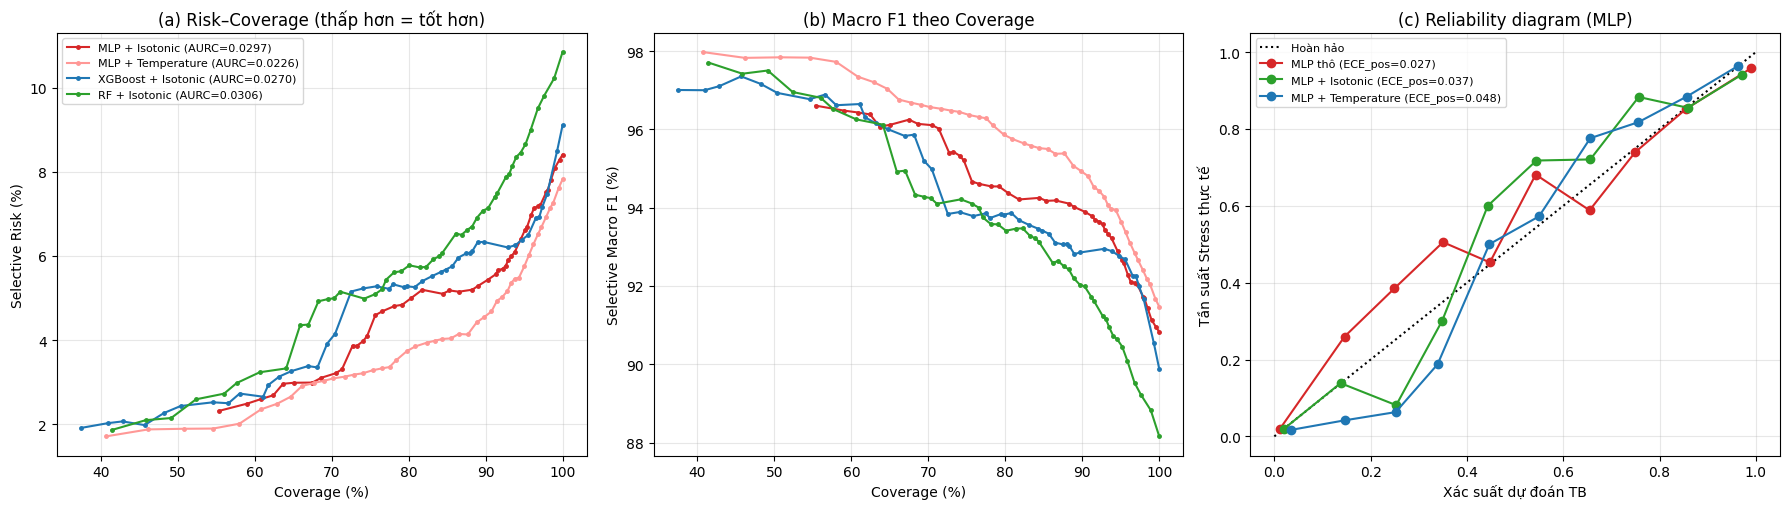

In [9]:
def rc_curve(y, p):
    cov, risk, f1m = [], [], []
    for t in TAU_GRID:
        s = sel_metrics(y, p, HM, t)
        if s["Coverage"] > 5: cov.append(s["Coverage"]); risk.append(s["Sel_Risk"] * 100); f1m.append(s["Sel_Macro_F1"] * 100)
    return np.array(cov), np.array(risk), np.array(f1m)

curves = {"MLP + Isotonic": PRED["MLP"]["iso"], "MLP + Temperature": PRED["MLP"]["temp"],
          "XGBoost + Isotonic": PRED["XGBoost"]["iso"], "RF + Isotonic": PRED["Random Forest"]["iso"]}
colors = {"MLP + Isotonic": "#d62728", "MLP + Temperature": "#ff9896", "XGBoost + Isotonic": "#1f77b4", "RF + Isotonic": "#2ca02c"}
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
for n, p in curves.items():
    c, r, f = rc_curve(y_all, p)
    ax[0].plot(c, r, "o-", ms=2.5, label=f"{n} (AURC={aurc(y_all, p):.4f})", color=colors[n]); ax[1].plot(c, f, "o-", ms=2.5, label=n, color=colors[n])
ax[0].set_xlabel("Coverage (%)"); ax[0].set_ylabel("Selective Risk (%)"); ax[0].set_title("(a) Risk–Coverage (thấp hơn = tốt hơn)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].set_xlabel("Coverage (%)"); ax[1].set_ylabel("Selective Macro F1 (%)"); ax[1].set_title("(b) Macro F1 theo Coverage"); ax[1].grid(alpha=.3)
ax[2].plot([0, 1], [0, 1], "k:", label="Hoàn hảo")
for v, n, col in [("raw", "MLP thô", "#d62728"), ("iso", "MLP + Isotonic", "#2ca02c"), ("temp", "MLP + Temperature", "#1f77b4")]:
    p = PRED["MLP"][v]; idx = np.minimum((p * 10).astype(int), 9)
    xs = [p[idx == k].mean() for k in range(10) if (idx == k).sum() >= 10]; ys = [y_all[idx == k].mean() for k in range(10) if (idx == k).sum() >= 10]
    ax[2].plot(xs, ys, "o-", color=col, label=f"{n} (ECE_pos={ece_pos(y_all, p):.3f})")
ax[2].set_xlabel("Xác suất dự đoán TB"); ax[2].set_ylabel("Tần suất Stress thực tế"); ax[2].set_title("(c) Reliability diagram (MLP)"); ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_mlp_risk_coverage_reliability.png", dpi=200); plt.show()

## 8. Theo từng subject và so sánh MLP với XGBoost
So sánh cặp trên 15 subject (LOSO), hiệu **MLP − XGBoost**, ở ba chế độ: *100% coverage* (không từ chối), *τ\* chọn trong inner validation* và *τ = 0.80* (cùng một ngưỡng cho cả hai, so sánh công bằng vì τ\* của hai mô hình có thể khác nhau nhiều). Wilcoxon cấp subject (có hiệu chỉnh Holm) và cluster bootstrap theo subject.

In [10]:
def per_subject(m, v="auto", fixed=None):
    p = PRED[m][v]; tau = np.full(len(df), fixed) if fixed is not None else TAUS[m][v]; rows = []
    for s in SUBJECTS:
        k = g_all == s; f, sl = full_metrics(y_all[k], p[k], HM[k]), sel_metrics(y_all[k], p[k], HM[k], tau[k])
        rows.append(dict(subject=s, Macro_F1=f["Macro_F1"], Stress_F1=f["Stress_F1"], Brier=f["Brier"], ECE_pos=f["ECE_pos"], AURC=f["AURC"],
                         Coverage=sl["Coverage"], Sel_Macro_F1=sl["Sel_Macro_F1"], Sel_Stress_F1=sl["Sel_Stress_F1"], Sel_Risk=sl["Sel_Risk"], FAR_sel=sl["FAR_motion"]))
    return pd.DataFrame(rows).set_index("subject")

def per_subject_seed(seed, m, v="auto", fixed=None):
    p = ALL_PRED[seed][m][v]
    tau = np.full(len(df), fixed) if fixed is not None else ALL_TAUS[seed][m][v]
    rows = []
    for s in SUBJECTS:
        k = g_all == s
        f = full_metrics(y_all[k], p[k], HM[k])
        sl = sel_metrics(y_all[k], p[k], HM[k], tau[k])
        rows.append(dict(subject=s, Macro_F1=f["Macro_F1"], Stress_F1=f["Stress_F1"],
                         Brier=f["Brier"], ECE_pos=f["ECE_pos"], AURC=f["AURC"],
                         Coverage=sl["Coverage"], Sel_Macro_F1=sl["Sel_Macro_F1"],
                         Sel_Stress_F1=sl["Sel_Stress_F1"], Sel_Risk=sl["Sel_Risk"], FAR_sel=sl["FAR_motion"]))
    return pd.DataFrame(rows).set_index("subject")

def mean_ps(m, v="auto", fixed=None):
    dfs = [per_subject_seed(seed, m, v, fixed) for seed in SEEDS]
    return sum(dfs) / len(dfs)

MODELS3 = ["MLP", "XGBoost", "Random Forest"]
# seed ref (cho hình & bảng per-subject chi tiết)
PS   = {m: per_subject(m, "auto") for m in MODELS3}                       # τ* inner val
PS80 = {m: per_subject(m, "auto", fixed=TAU_PAPER) for m in MODELS3}      # τ = 0.80
ps_cmp = pd.concat({m: PS[m][["Macro_F1", "Stress_F1", "Coverage", "Sel_Macro_F1", "Sel_Stress_F1", "Sel_Risk"]] for m in PS}, axis=1)
ps_cmp.to_csv(f"{OUT}/per_subject_mlp_vs_xgb_rf.csv"); display(ps_cmp.round(3))
display(pd.DataFrame({m: PS[m].agg(["mean", "std"]).T.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1) for m in PS}))
print("Số subject mà MLP không phản hồi (coverage < 5%) ở τ*:", list(PS["MLP"].index[PS["MLP"].Coverage < 5]))

# trung bình per-subject qua seed → Wilcoxon ổn định hơn
PS_auto   = {m: mean_ps(m, "auto") for m in MODELS3}
PS_raw    = {m: mean_ps(m, "raw")  for m in MODELS3}
PS80_auto = {m: mean_ps(m, "auto", fixed=TAU_PAPER) for m in MODELS3}
PS80_raw  = {m: mean_ps(m, "raw",  fixed=TAU_PAPER) for m in MODELS3}

def holm(p):
    p = np.asarray(p, float); m = len(p); o = np.argsort(p); adj = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[o])); out = np.empty(m); out[o] = adj; return out
def paired(a, b, name):
    a, b = np.asarray(a, float), np.asarray(b, float); ok = ~(np.isnan(a) | np.isnan(b)); d = (a - b)[ok]; nz = d[d != 0]
    if len(nz) == 0: return dict(metric=name, n=int(ok.sum()), n_nonzero=0, median_diff=0.0, p=1.0, rank_biserial=0.0)
    rk = pd.Series(np.abs(nz)).rank().values
    return dict(metric=name, n=int(ok.sum()), n_nonzero=len(nz), median_diff=float(np.median(d)), p=wilcoxon(a[ok], b[ok]).pvalue,
                rank_biserial=(rk[nz > 0].sum() - rk[nz < 0].sum()) / rk.sum())
def compare(A, B, mets):
    t = pd.DataFrame([paired(A[c], B[c], c) for c in mets]).set_index("metric"); t["p_holm"] = holm(t.p.values); return t

M_FULL = ["Macro_F1", "Stress_F1", "Brier", "ECE_pos", "AURC"]
M_SEL  = ["Coverage", "Sel_Macro_F1", "Sel_Risk", "FAR_sel"]
tw = pd.concat({
    "100% coverage (auto)": compare(PS_auto["MLP"], PS_auto["XGBoost"], M_FULL),
    "100% coverage (raw)":  compare(PS_raw["MLP"],  PS_raw["XGBoost"],  M_FULL),
    "τ* (auto)":            compare(PS_auto["MLP"], PS_auto["XGBoost"], M_SEL),
    "τ* (raw)":             compare(PS_raw["MLP"],  PS_raw["XGBoost"],  M_SEL),
    "τ=0.80 (auto)":        compare(PS80_auto["MLP"], PS80_auto["XGBoost"], M_SEL),
    "τ=0.80 (raw)":         compare(PS80_raw["MLP"],  PS80_raw["XGBoost"],  M_SEL),
})
tw.to_csv(f"{OUT}/wilcoxon_mlp_vs_xgb.csv"); display(tw.round(4))
print("Hiệu = MLP − XGBoost. Brier/ECE_pos/AURC/Sel_Risk/FAR_sel: âm = MLP tốt hơn; F1/Coverage: dương = MLP tốt hơn.")
print("Đã có kiểm định cho cả bản raw và auto (mean over seeds).")

# bootstrap (dùng seed ref + variant auto như trước)
rng = np.random.default_rng(SEEDS[0]); idx = {s: np.where(g_all == s)[0] for s in SUBJECTS}
def pooled(m, ii, fixed=None, v="auto"):
    p = PRED[m][v][ii]; tau = np.full(len(ii), fixed) if fixed is not None else TAUS[m][v][ii]
    y, hm = y_all[ii], HM[ii]
    f, sl = full_metrics(y, p, hm), sel_metrics(y, p, hm, tau)
    return dict(Macro_F1=f["Macro_F1"], Brier=f["Brier"], ECE_pos=f["ECE_pos"], AURC=f["AURC"], Coverage=sl["Coverage"],
                Sel_Macro_F1=sl["Sel_Macro_F1"], Sel_Risk=sl["Sel_Risk"], FAR_sel=sl["FAR_motion"])
res = {}
for mode, ft, v in [("τ* (auto)", None, "auto"), ("τ=0.80 (auto)", TAU_PAPER, "auto"),
                    ("τ* (raw)", None, "raw"), ("τ=0.80 (raw)", TAU_PAPER, "raw")]:
    boot = []
    for _ in range(1000):
        ii = np.concatenate([idx[s] for s in rng.choice(SUBJECTS, 15, replace=True)])
        a, b = pooled("MLP", ii, ft, v), pooled("XGBoost", ii, ft, v)
        boot.append({k: a[k] - b[k] for k in a})
    boot = pd.DataFrame(boot); full_ii = np.arange(len(df))
    a, b = pooled("MLP", full_ii, ft, v), pooled("XGBoost", full_ii, ft, v)
    res[mode] = pd.DataFrame({"MLP_minus_XGB": {k: a[k] - b[k] for k in a},
                              "CI95_low": boot.quantile(.025), "CI95_high": boot.quantile(.975)})
ci = pd.concat(res); ci["CI_chứa_0"] = (ci.CI95_low <= 0) & (ci.CI95_high >= 0)
ci.to_csv(f"{OUT}/bootstrap_diff_mlp_vs_xgb.csv"); display(ci.round(4))

MLP                                                         \
        Macro_F1 Stress_F1 Coverage Sel_Macro_F1 Sel_Stress_F1 Sel_Risk   
subject                                                                   
S1         0.844     0.777   65.976        0.782         0.571    0.013   
S2         0.902     0.881   67.155        0.947         0.942    0.052   
S3         1.000     1.000   95.362        1.000         1.000    0.000   
S4         0.948     0.933   94.051        0.970         0.962    0.027   
S5         1.000     1.000   97.151        1.000         1.000    0.000   
S6         0.933     0.917   81.766        0.972         0.968    0.028   
S7         0.969     0.959   75.284        1.000         1.000    0.000   
S8         0.702     0.548   52.857        0.464         0.000    0.135   
S9         0.912     0.884   32.877        1.000         1.000    0.000   
S10        0.963     0.951   97.479        0.974         0.965    0.023   
S11        0.979     0.973   96.045        1.000         1.000    0.000   
S12        0.978     0.972   81.793        1.000         1.000    0.000   
S13        0.600     0.617   25.978        0.419         0.838    0.280   
S14        0.997     0.996   54.213        1.000         1.000    0.000   
S15        0.955     0.942    0.000          NaN           NaN      NaN   

         XGBoost                                                         \
        Macro_F1 Stress_F1 Coverage Sel_Macro_F1 Sel_Stress_F1 Sel_Risk   
subject                                                                   
S1         0.808     0.718   63.609        0.496         0.000    0.014   
S2         0.716     0.712   40.469        0.925         0.939    0.072   
S3         1.000     1.000  100.000        1.000         1.000    0.000   
S4         0.938     0.921   48.159        1.000         1.000    0.000   
S5         0.954     0.942   51.567        1.000         1.000    0.000   
S6         0.924     0.906   23.647        1.000         1.000    0.000   
S7         0.932     0.909   75.568        1.000         1.000    0.000   
S8         0.764     0.648   81.429        0.694         0.466    0.137   
S9         0.988     0.986    3.014        1.000         1.000    0.000   
S10        1.000     1.000   72.549        1.000         1.000    0.000   
S11        0.919     0.890    9.887        1.000         1.000    0.000   
S12        0.526     0.247   63.025        0.490         0.000    0.040   
S13        0.929     0.908    8.659        1.000         1.000    0.000   
S14        1.000     1.000   32.584        1.000         1.000    0.000   
S15        0.917     0.893   41.803        1.000         1.000    0.000   

        Random Forest                                                         
             Macro_F1 Stress_F1 Coverage Sel_Macro_F1 Sel_Stress_F1 Sel_Risk  
subject                                                                       
S1              0.867     0.810   92.604        0.886         0.833    0.089  
S2              0.659     0.676   49.560        0.802         0.843    0.189  
S3              1.000     1.000   32.464        1.000         1.000    0.000  
S4              0.954     0.942   54.108        1.000         1.000    0.000  
S5              0.916     0.898   99.430        0.922         0.904    0.074  
S6              0.853     0.829   67.236        0.970         0.970    0.030  
S7              0.952     0.937   87.500        1.000         1.000    0.000  
S8              0.745     0.617   74.857        0.709         0.465    0.088  
S9              0.843     0.782   58.082        1.000         1.000    0.000  
S10             0.997     0.996   69.748        1.000         1.000    0.000  
S11             0.965     0.954   34.181        1.000         1.000    0.000  
S12             0.727     0.593   74.510        0.510         0.115    0.173  
S13             0.816     0.784   32.402        1.000         1.000    0.000  
S14             1.000     1.000   49.719       

,MLP,XGBoost,Random Forest
Macro_F1,0.912 ± 0.116,0.888 ± 0.132,0.877 ± 0.107
Stress_F1,0.890 ± 0.138,0.845 ± 0.199,0.843 ± 0.135
Brier,0.065 ± 0.067,0.078 ± 0.057,0.082 ± 0.065
ECE_pos,0.128 ± 0.077,0.147 ± 0.074,0.138 ± 0.068
AURC,0.035 ± 0.081,0.022 ± 0.037,0.029 ± 0.045
Coverage,67.866 ± 29.776,47.731 ± 28.804,59.137 ± 25.094
Sel_Macro_F1,0.895 ± 0.201,0.907 ± 0.186,0.920 ± 0.143
Sel_Stress_F1,0.875 ± 0.277,0.827 ± 0.363,0.875 ± 0.253
Sel_Risk,0.040 ± 0.078,0.018 ± 0.039,0.043 ± 0.066
FAR_sel,5.841 ± 13.827,0.699 ± 2.521,2.647 ± 7.658


Số subject mà MLP không phản hồi (coverage < 5%) ở τ*: ['S15']


n  n_nonzero  median_diff       p  \
                     metric                                             
100% coverage (auto) Macro_F1      15         14       0.0012  0.9750   
                     Stress_F1     15         14       0.0014  0.9250   
                     Brier         15         15      -0.0031  0.6788   
                     ECE_pos       15         15      -0.0230  0.3894   
                     AURC          15         14       0.0000  0.8753   
100% coverage (raw)  Macro_F1      15         14       0.0000  0.6832   
                     Stress_F1     15         14       0.0000  0.6378   
                     Brier         15         15      -0.0013  0.4212   
                     ECE_pos       15         15      -0.0001  0.6788   
                     AURC          15         14       0.0000  0.7299   
τ* (auto)            Coverage      15         15      20.3825  0.0015   
                     Sel_Macro_F1  13         10       0.0000  1.0000   
                     Sel_Risk      13         10       0.0030  0.2324   
                     FAR_sel       11          5       0.0000  0.1875   
τ* (raw)             Coverage      15         15       0.9659  0.6387   
                     Sel_Macro_F1  15         12       0.0000  0.9375   
                     Sel_Risk      15         12       0.0000  0.4802   
                     FAR_sel       13          7       0.0000  0.8125   
τ=0.80 (auto)        Coverage      15         15       3.9776  0.1876   
                     Sel_Macro_F1  15         12       0.0000  0.9375   
                     Sel_Risk      15         12       0.0000  0.6379   
                     FAR_sel       13          5       0.0000  0.6250   
τ=0.80 (raw)         Coverage      15         15      -1.0826  0.2078   
                     Sel_Macro_F1  15         14       0.0000  0.5098   
                     Sel_Risk      15         14      -0.0257  0.1401   
                     FAR_sel       13          8       0.0000  0.4609   

                                   rank_biserial  p_holm  
                     metric                               
100% coverage (auto) Macro_F1            -0.0095  1.0000  
                     Stress_F1            0.0286  1.0000  
                     Brier               -0.1333  1.0000  
                     ECE_pos             -0.2667  1.0000  
                     AURC                 0.0476  1.0000  
100% coverage (raw)  Macro_F1             0.1238  1.0000  
                     Stress_F1            0.1429  1.0000  
                     Brier               -0.2500  1.0000  
                     ECE_pos             -0.1333  1.0000  
                     AURC                -0.1048  1.0000  
τ* (auto)            Coverage             0.8667  0.0061  
                     Sel_Macro_F1        -0.0182  1.0000  
                     Sel_Risk             0.4545  0.5625  
                     FAR_sel              0.7333  0.5625  
τ* (raw)             Coverage             0.1500  1.0000  
                     Sel_Macro_F1        -0.0256  1.0000  
                     Sel_Risk            -0.2308  1.0000  
                     FAR_sel              0.1429  1.0000  
τ=0.80 (auto)        Coverage             0.4000  0.7505  
                     Sel_Macro_F1        -0.0256  1.0000  
                     Sel_Risk            -0.1538  1.0000  
                     FAR_sel              0.3333  1.0000  
τ=0.80 (raw)         Coverage            -0.3833  0.6233  
                     Sel_Macro_F1         0.2000  0.9219  
                     Sel_Risk            -0.4476  0.5606  
                     FAR_sel             -0.3333  0.9219

Hiệu = MLP − XGBoost. Brier/ECE_pos/AURC/Sel_Risk/FAR_sel: âm = MLP tốt hơn; F1/Coverage: dương = MLP tốt hơn.
Đã có kiểm định cho cả bản raw và auto (mean over seeds).


MLP_minus_XGB  CI95_low  CI95_high  CI_chứa_0
τ* (auto)     Macro_F1             0.0159   -0.0540     0.0857       True
              Brier               -0.0125   -0.0412     0.0215       True
              ECE_pos             -0.0099   -0.0597     0.0312       True
              AURC                -0.0044   -0.0216     0.0213       True
              Coverage            20.0982    3.7178    35.6931      False
              Sel_Macro_F1         0.0035   -0.0245     0.0454       True
              Sel_Risk             0.0012   -0.0206     0.0241       True
              FAR_sel              5.0847    0.0000    13.1095       True
τ=0.80 (auto) Macro_F1             0.0159   -0.0553     0.0932       True
              Brier               -0.0125   -0.0445     0.0246       True
              ECE_pos             -0.0099   -0.0612     0.0371       True
              AURC                -0.0044   -0.0229     0.0217       True
              Coverage             5.8935   -6.7447    17.1137       True
              Sel_Macro_F1         0.0117   -0.0256     0.0513       True
              Sel_Risk            -0.0063   -0.0374     0.0282       True
              FAR_sel              2.0339   -5.4355     8.5450       True
τ* (raw)      Macro_F1             0.0328   -0.0228     0.0906       True
              Brier               -0.0343   -0.0787     0.0077       True
              ECE_pos             -0.0492   -0.0976     0.0080       True
              AURC                -0.0181   -0.0452     0.0038       True
              Coverage             1.9456   -8.8139    11.8337       True
              Sel_Macro_F1         0.0418   -0.0041     0.0931       True
              Sel_Risk            -0.0405   -0.0864     0.0013       True
              FAR_sel             -0.3390   -5.6081     4.2946       True
τ=0.80 (raw)  Macro_F1             0.0328   -0.0227     0.0883       True
              Brier               -0.0343   -0.0779     0.0066       True
              ECE_pos             -0.0492   -0.0985     0.0068       True
              AURC                -0.0181   -0.0453     0.0025       True
              Coverage            -1.1711   -6.5048     4.7053       True
              Sel_Macro_F1         0.0474   -0.0029     0.1038       True
              Sel_Risk            -0.0457   -0.1005     0.0010       True
              FAR_sel             -2.7119  -12.2957     4.0823       True

## 9. Hình theo từng subject (MLP vs XGBoost)

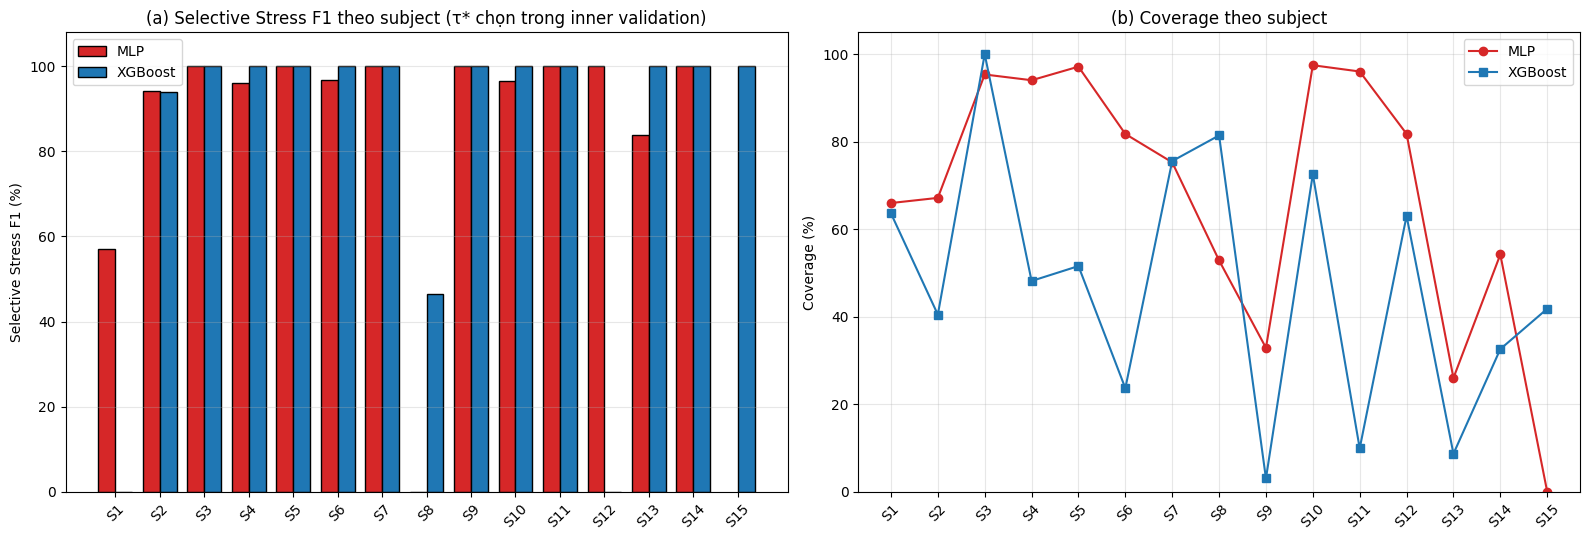

In [11]:
x = np.arange(15); w = 0.38
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
ax[0].bar(x - w/2, PS["MLP"].Sel_Stress_F1 * 100, w, label="MLP", color="#d62728", edgecolor="k")
ax[0].bar(x + w/2, PS["XGBoost"].Sel_Stress_F1 * 100, w, label="XGBoost", color="#1f77b4", edgecolor="k")
ax[0].set_xticks(x); ax[0].set_xticklabels(SUBJECTS, rotation=45); ax[0].set_ylabel("Selective Stress F1 (%)"); ax[0].set_ylim(0, 108)
ax[0].set_title("(a) Selective Stress F1 theo subject (τ* chọn trong inner validation)"); ax[0].legend(); ax[0].grid(axis="y", alpha=.3)
ax[1].plot(x, PS["MLP"].Coverage, "o-", color="#d62728", label="MLP"); ax[1].plot(x, PS["XGBoost"].Coverage, "s-", color="#1f77b4", label="XGBoost")
ax[1].set_xticks(x); ax[1].set_xticklabels(SUBJECTS, rotation=45); ax[1].set_ylabel("Coverage (%)"); ax[1].set_ylim(0, 105)
ax[1].set_title("(b) Coverage theo subject"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_mlp_per_subject.png", dpi=200); plt.show()

## 10. Tóm tắt để dán vào báo cáo

In [12]:
def line(m, v, rule):
    r = tab_sel.loc[(m, v, rule)]; f = tab_full.loc[(m, v)]
    return (f"{m:<14}{v:<5}| 100%: MacroF1={f.Macro_F1*100:5.2f} ECE_pos={f.ECE_pos:.4f} Brier={f.Brier:.4f} FAR={f.FAR_motion:5.2f}%  "
            f"|| {rule[:22]:<22}: Cov={r.Coverage:5.1f}% Risk={r.Sel_Risk*100:4.1f}% MacroF1={r.Sel_Macro_F1*100:5.2f} FAR={r.FAR_motion:5.2f}%")
RULE_STAR = f"τ* (inner val, risk≤{R_TARGET})"
for m, v in [("MLP", "auto"), ("MLP", "iso"), ("MLP", "raw"), ("XGBoost", "iso"), ("XGBoost", "raw"), ("Random Forest", "iso")]:
    if (m, v) in tab_full.index and (m, v, RULE_STAR) in tab_sel.index:
        print(line(m, v, RULE_STAR))
print(f"\nτ* TB (MLP, seed ref): {INFO['MLP'].tau_star.mean():.3f} ± {INFO['MLP'].tau_star.std():.3f}")
print(f"Số seed: {len(SEEDS)} | TUNE={TUNE}")
print("Hiệu MLP − XGBoost (Wilcoxon mean-over-seeds; xem bảng tw):")
display(tw.round(4))

MLP           auto | 100%: MacroF1=88.95 ECE_pos=0.0489 Brier=0.0781 FAR=24.00%  || τ* (inner val, risk≤0.: Cov= 69.9% Risk= 3.5% MacroF1=96.09 FAR= 7.66%
MLP           iso  | 100%: MacroF1=88.83 ECE_pos=0.0405 Brier=0.0819 FAR=25.63%  || τ* (inner val, risk≤0.: Cov= 65.9% Risk= 3.4% MacroF1=95.92 FAR= 7.32%
MLP           raw  | 100%: MacroF1=88.49 ECE_pos=0.0504 Brier=0.0793 FAR=21.69%  || τ* (inner val, risk≤0.: Cov= 81.5% Risk= 5.1% MacroF1=94.48 FAR=11.53%
XGBoost       iso  | 100%: MacroF1=90.09 ECE_pos=0.0532 Brier=0.0774 FAR=10.51%  || τ* (inner val, risk≤0.: Cov= 48.1% Risk= 2.8% MacroF1=96.39 FAR= 0.68%
XGBoost       raw  | 100%: MacroF1=87.86 ECE_pos=0.0745 Brier=0.0933 FAR=12.61%  || τ* (inner val, risk≤0.: Cov= 78.3% Risk= 6.4% MacroF1=93.03 FAR= 3.59%
Random Forest iso  | 100%: MacroF1=88.50 ECE_pos=0.0276 Brier=0.0801 FAR=18.31%  || τ* (inner val, risk≤0.: Cov= 59.2% Risk= 3.9% MacroF1=95.42 FAR= 1.29%

τ* TB (MLP, seed ref): 0.820 ± 0.086
Số seed: 5 | TUNE=False
Hiệu MLP

n  n_nonzero  median_diff       p  \
                     metric                                             
100% coverage (auto) Macro_F1      15         14       0.0012  0.9750   
                     Stress_F1     15         14       0.0014  0.9250   
                     Brier         15         15      -0.0031  0.6788   
                     ECE_pos       15         15      -0.0230  0.3894   
                     AURC          15         14       0.0000  0.8753   
100% coverage (raw)  Macro_F1      15         14       0.0000  0.6832   
                     Stress_F1     15         14       0.0000  0.6378   
                     Brier         15         15      -0.0013  0.4212   
                     ECE_pos       15         15      -0.0001  0.6788   
                     AURC          15         14       0.0000  0.7299   
τ* (auto)            Coverage      15         15      20.3825  0.0015   
                     Sel_Macro_F1  13         10       0.0000  1.0000   
                     Sel_Risk      13         10       0.0030  0.2324   
                     FAR_sel       11          5       0.0000  0.1875   
τ* (raw)             Coverage      15         15       0.9659  0.6387   
                     Sel_Macro_F1  15         12       0.0000  0.9375   
                     Sel_Risk      15         12       0.0000  0.4802   
                     FAR_sel       13          7       0.0000  0.8125   
τ=0.80 (auto)        Coverage      15         15       3.9776  0.1876   
                     Sel_Macro_F1  15         12       0.0000  0.9375   
                     Sel_Risk      15         12       0.0000  0.6379   
                     FAR_sel       13          5       0.0000  0.6250   
τ=0.80 (raw)         Coverage      15         15      -1.0826  0.2078   
                     Sel_Macro_F1  15         14       0.0000  0.5098   
                     Sel_Risk      15         14      -0.0257  0.1401   
                     FAR_sel       13          8       0.0000  0.4609   

                                   rank_biserial  p_holm  
                     metric                               
100% coverage (auto) Macro_F1            -0.0095  1.0000  
                     Stress_F1            0.0286  1.0000  
                     Brier               -0.1333  1.0000  
                     ECE_pos             -0.2667  1.0000  
                     AURC                 0.0476  1.0000  
100% coverage (raw)  Macro_F1             0.1238  1.0000  
                     Stress_F1            0.1429  1.0000  
                     Brier               -0.2500  1.0000  
                     ECE_pos             -0.1333  1.0000  
                     AURC                -0.1048  1.0000  
τ* (auto)            Coverage             0.8667  0.0061  
                     Sel_Macro_F1        -0.0182  1.0000  
                     Sel_Risk             0.4545  0.5625  
                     FAR_sel              0.7333  0.5625  
τ* (raw)             Coverage             0.1500  1.0000  
                     Sel_Macro_F1        -0.0256  1.0000  
                     Sel_Risk            -0.2308  1.0000  
                     FAR_sel              0.1429  1.0000  
τ=0.80 (auto)        Coverage             0.4000  0.7505  
                     Sel_Macro_F1        -0.0256  1.0000  
                     Sel_Risk            -0.1538  1.0000  
                     FAR_sel              0.3333  1.0000  
τ=0.80 (raw)         Coverage            -0.3833  0.6233  
                     Sel_Macro_F1         0.2000  0.9219  
                     Sel_Risk            -0.4476  0.5606  
                     FAR_sel             -0.3333  0.9219

## 11. Lưu kết quả lên Google Drive

In [13]:
try:
    from google.colab import drive
    import shutil
    drive.mount("/content/drive")
    DRIVE_DIR = "/content/drive/MyDrive/DSR301m_project_group4/result/deeplearning"
    os.makedirs(DRIVE_DIR, exist_ok=True); shutil.copytree(OUT, DRIVE_DIR, dirs_exist_ok=True)
    print("Đã lưu vào:", DRIVE_DIR); print(sorted(os.listdir(DRIVE_DIR)))
except ImportError:
    print("Không chạy trên Colab → bỏ qua bước lưu Drive. Kết quả nằm trong:", OUT)

Mounted at /content/drive
Đã lưu vào: /content/drive/MyDrive/DSR301m_project_group4/result/deeplearning
['bootstrap_diff_mlp_vs_xgb.csv', 'fig_mlp_per_subject.png', 'fig_mlp_risk_coverage_reliability.png', 'oof_predictions_mlp_seed42.csv', 'per_subject_mlp_vs_xgb_rf.csv', 'table_full_coverage_mlp_all_seeds.csv', 'table_full_coverage_mlp_mean.csv', 'table_selective_mlp_all_seeds.csv', 'table_selective_mlp_mean.csv', 'wilcoxon_mlp_vs_xgb.csv']
